In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

motif_length = 3
persite_mu = 1.34*10**(-8)

In [2]:
#Total sites refer to the total amount across all regions considered
def get_normalizer_mut_constant(mutability_data, persite_mu):
    #Calculate the constant to normalize the total mutation rate equal to the average per base mutation rate
    # mutability_data is a data frame with the mutability, regions, chromosome and sequence length
    # mean_mutability is the average relative mutation rate of a genomic region

    #multiply each mutability score by it's length to obtain a weighted sum
    mutTimeslength = np.sum(mutability_data["mean_mutability"]*mutability_data["numb_sites"])
    total_numb_sites = mutability_data["numb_sites"].sum()

    #divide by the total number of sites to obtain the average mutability score across all sites
    mean_mutability = mutTimeslength/total_numb_sites

    #mu = c*mutability. Divide mean_mu/mean_mutability to obtain the constant
    constant_mu = persite_mu/mean_mutability

    return constant_mu

In [3]:
df = pd.read_csv("output_data/mutability_motiflength" + str(motif_length) + ".csv")
df

,Region,Chromosome,sitesTimesMutability,mean_mutability,numb_sites
0,cds,1,2.341549e+06,0.716698,3267139
1,introns_nonUTR,1,2.861388e+07,0.519672,55061404
2,introns3UTR,1,4.362524e+05,0.668821,652273
3,introns5UTR,1,4.657880e+05,0.674044,691037
4,intronsAR,1,2.825759e+07,0.539402,52386884
...,...,...,...,...,...
179,introns5UTR,X,1.647577e+05,0.632832,260352
180,intronsAR,X,1.346033e+07,0.524239,25675959
181,distalIG,X,6.903236e+06,0.475511,14517508
182,proximal5IG,X,1.063449e+06,0.517326,2055666


# Calculating mean mutation rates per region

/tmp/ipykernel_573466/1462388849.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=12)
/tmp/ipykernel_573466/1462388849.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


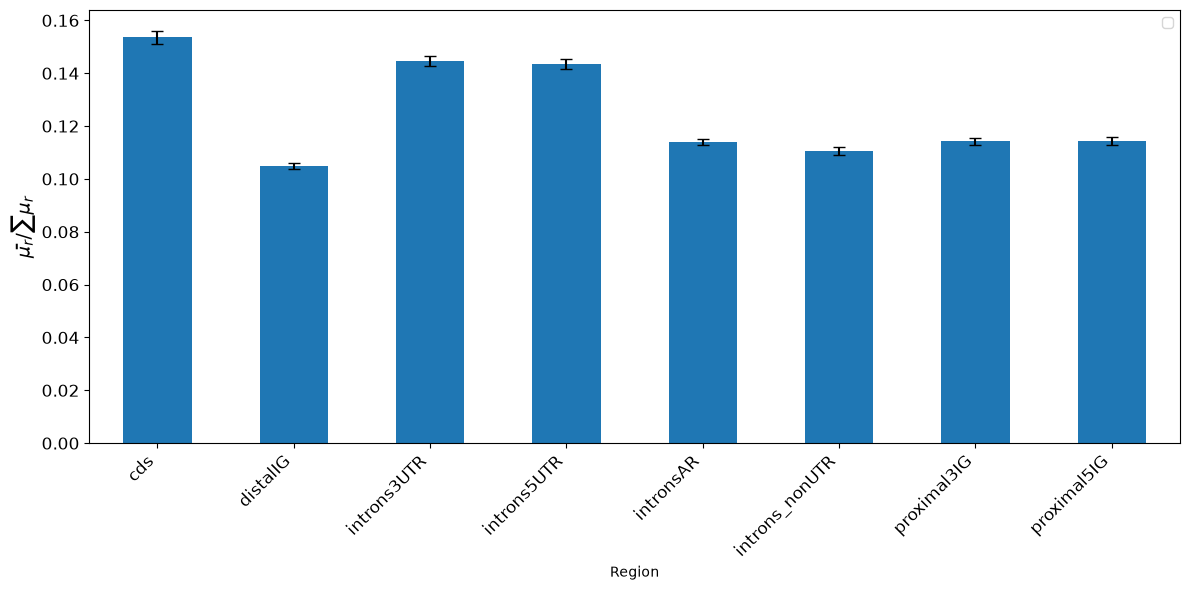

In [4]:
constant_mu = get_normalizer_mut_constant(df, persite_mu)

mutability_data = df.drop(columns=['numb_sites'], errors='ignore')

mutationrate_data = mutability_data.copy()
mutationrate_data["mean_mutation_rate"] = mutationrate_data["mean_mutability"]*constant_mu
mutationrate_data = mutationrate_data[["Region", "Chromosome", "mean_mutation_rate"]]
stats_mutrate = mutationrate_data.groupby(['Region'])['mean_mutation_rate'].agg(['mean', 'sem']).unstack()

sum_of_means = stats_mutrate.loc["mean"].sum()

#I'm computing the relative contribution of a region mutation rate compared to the total sum of mu. 
relative_mutationrate_data = mutationrate_data.copy()
relative_mutationrate_data["relative_mean_mutation_rate"] = relative_mutationrate_data["mean_mutation_rate"]/sum_of_means
relative_mutationrate_data = relative_mutationrate_data[["Region", "Chromosome", "relative_mean_mutation_rate"]]

stats_relative_mutrate = relative_mutationrate_data.groupby(['Region'])['relative_mean_mutation_rate'].agg(['mean', 'sem']).unstack()

mean_relative_mutationrate_data = stats_relative_mutrate['mean']
err_relative_mutationrate_data = stats_relative_mutrate['sem']

ax = mean_relative_mutationrate_data.plot(
    kind='bar',
    yerr=err_relative_mutationrate_data,
    capsize=4,
    figsize=(12, 6)
)
ax.set_ylabel(r'$\bar{\mu_r}/\sum\mu_r$', fontsize=14)
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)
ax.legend(fontsize=12)
ax.legend()
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [5]:
stats_mutrate.to_csv("output_data/average_mutrates_motiflength" + str(motif_length) + "_mean_sem.csv")
stats_mutrate

      Region        
mean  cds               1.855308e-08
      distalIG          1.267585e-08
      introns3UTR       1.747793e-08
      introns5UTR       1.734119e-08
      intronsAR         1.376711e-08
      introns_nonUTR    1.337099e-08
      proximal3IG       1.380438e-08
      proximal5IG       1.382104e-08
sem   cds               3.088882e-10
      distalIG          1.439285e-10
      introns3UTR       2.326809e-10
      introns5UTR       2.176704e-10
      intronsAR         1.172842e-10
      introns_nonUTR    1.766353e-10
      proximal3IG       1.653092e-10
      proximal5IG       1.661534e-10
dtype: float64

# Calculating U_T per region

In [6]:
df

,Region,Chromosome,sitesTimesMutability,mean_mutability,numb_sites
0,cds,1,2.341549e+06,0.716698,3267139
1,introns_nonUTR,1,2.861388e+07,0.519672,55061404
2,introns3UTR,1,4.362524e+05,0.668821,652273
3,introns5UTR,1,4.657880e+05,0.674044,691037
4,intronsAR,1,2.825759e+07,0.539402,52386884
...,...,...,...,...,...
179,introns5UTR,X,1.647577e+05,0.632832,260352
180,intronsAR,X,1.346033e+07,0.524239,25675959
181,distalIG,X,6.903236e+06,0.475511,14517508
182,proximal5IG,X,1.063449e+06,0.517326,2055666


In [7]:
constant_mu = get_normalizer_mut_constant(df, persite_mu)

df["UT"] = 2*constant_mu*df["sitesTimesMutability"] 
UT_data = df.drop(columns=['mean_mutability', 'numb_sites', 'sitesTimesMutability'], errors='ignore')
UT_data

region_UT = (
    UT_data.groupby("Region", as_index=False)["UT"].sum()
)
region_UT

UT_allregions = UT_data["UT"].sum()
UT_allregions


np.float64(42.56143095333597)

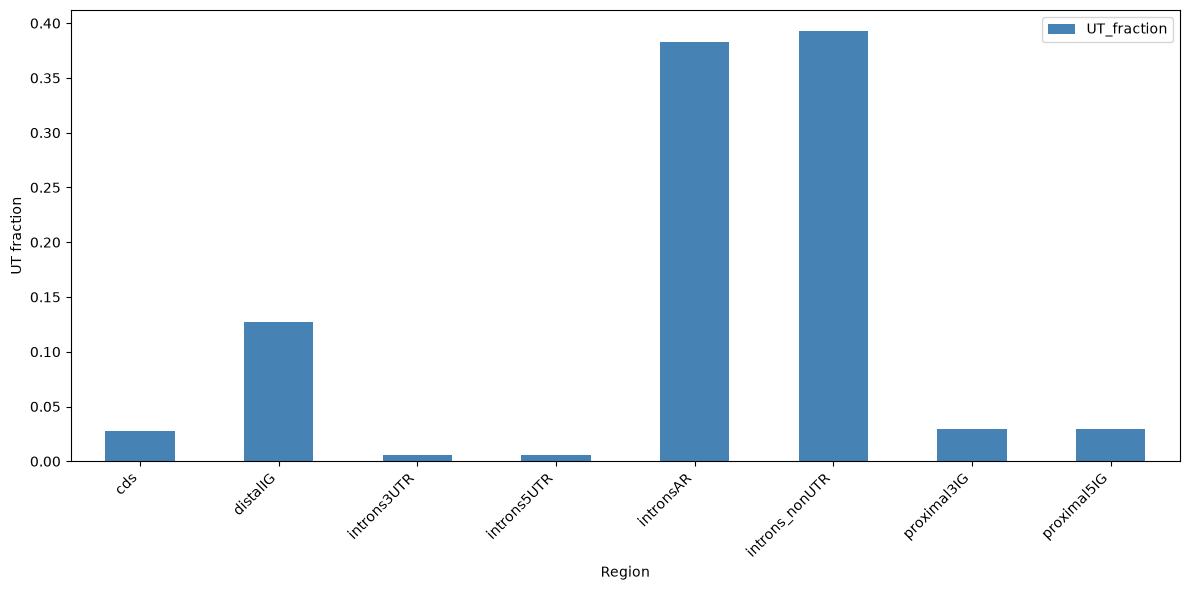

In [8]:
constant_mu = get_normalizer_mut_constant(df, persite_mu)

df["UT"] = 2*constant_mu*df["sitesTimesMutability"] 
UT_data = df.drop(columns=['mean_mutability', 'numb_sites', 'sitesTimesMutability'], errors='ignore')

region_UT = (
    UT_data.groupby("Region", as_index=False)["UT"].sum()
)

UT_allregions = UT_data["UT"].sum()

region_UT["UT_fraction"] = (
    region_UT["UT"] / UT_allregions
)

ax = region_UT.plot(
    x="Region",
    y="UT_fraction",
    kind="bar",
    figsize=(12, 6),
    color="steelblue"
)

ax.set_ylabel("UT fraction")
ax.set_xlabel("Region")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [9]:
region_UT.to_csv("output_data/UT_perregion_motiflength" + str(motif_length) + ".csv")
region_UT

,Region,UT,UT_fraction
0,cds,1.195432,0.028087
1,distalIG,5.418376,0.127307
2,introns3UTR,0.232706,0.005468
3,introns5UTR,0.231799,0.005446
4,intronsAR,16.284617,0.382614
5,introns_nonUTR,16.700769,0.392392
6,proximal3IG,1.249524,0.029358
7,proximal5IG,1.248207,0.029327


# Calculating total length per region

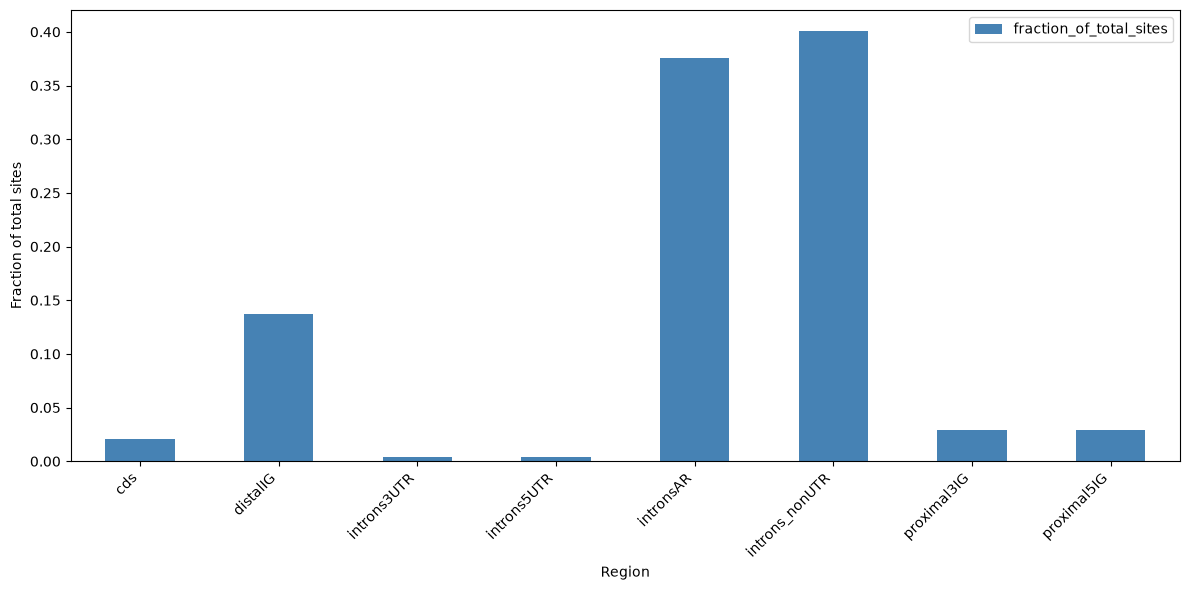

In [10]:
length_data = df.drop(columns=['mean_mutability'], errors='ignore')

total_numb_sites = length_data["numb_sites"].sum()

region_numb_sites = (
    length_data.groupby("Region", as_index=False)["numb_sites"]
    .sum()
    .rename(columns={"numb_sites": "total_numb_sites"})
)

region_numb_sites["fraction_of_total_sites"] = (
    region_numb_sites["total_numb_sites"] / total_numb_sites
)

ax = region_numb_sites.plot(
    x="Region",
    y="fraction_of_total_sites",
    kind="bar",
    figsize=(12, 6),
    color="steelblue"
)

ax.set_ylabel("Fraction of total sites")
ax.set_xlabel("Region")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [11]:
region_numb_sites.to_csv("output_data/length_perregion.csv")
region_numb_sites

,Region,total_numb_sites,fraction_of_total_sites
0,cds,32311773,0.020346
1,distalIG,218153499,0.137366
2,introns3UTR,6693941,0.004215
3,introns5UTR,6727706,0.004236
4,intronsAR,596828432,0.375810
5,introns_nonUTR,635773378,0.400332
6,proximal3IG,45854232,0.028873
7,proximal5IG,45770549,0.028821


# What is the total number of sites computed?

In [12]:
total_numb_sites/(10**9)

np.float64(1.58811351)

# Test that the average mutation rate is correct

In [13]:
mean_mutrate = sum(mutationrate_data["mean_mutation_rate"]*length_data["numb_sites"])/sum(length_data["numb_sites"])
mean_mutrate

1.3400000000000001e-08